In [ ]:
Soal 1 — Bank Account Race Condition

In [ ]:
Sel 1 — tanpa lock

In [1]:
import threading
import time

saldo = 1_000_000

def tarik_setor_tanpa_lock(jumlah_operasi):
    global saldo
    for _ in range(jumlah_operasi):
        saldo -= 1   # tarik 1
        saldo += 1   # setor 1

JUMLAH_THREAD = 10
JUMLAH_OPERASI = 10_000

threads = [threading.Thread(target=tarik_setor_tanpa_lock, args=(JUMLAH_OPERASI,))
           for _ in range(JUMLAH_THREAD)]

start = time.perf_counter()
for t in threads: t.start()
for t in threads: t.join()
waktu_tanpa_lock = time.perf_counter() - start

print("===== TANPA LOCK =====")
print(f"Saldo seharusnya : {1_000_000:,}")
print(f"Saldo akhir      : {saldo:,}")
print(f"Sesuai?          : {'✅ YA' if saldo == 1_000_000 else '❌ TIDAK (race condition terjadi)'}")
print(f"Waktu eksekusi   : {waktu_tanpa_lock:.4f} detik")

===== TANPA LOCK =====
Saldo seharusnya : 1,000,000
Saldo akhir      : 1,000,000
Sesuai?          : ✅ YA
Waktu eksekusi   : 0.0253 detik


pada beberapa run, saldo akhir bisa saja tetap 1.000.000 meski tanpa lock. Ini bukan berarti race condition tidak ada — saldo -= 1; saldo += 1 tetap terdiri dari beberapa bytecode (load → hitung → simpan) yang tidak atomik, tapi celah waktu antar-thread untuk saling menimpa sangat sempit sehingga tidak selalu "tertangkap" di setiap run (persis seperti yang dijelaskan pada materi bagian 3). Untuk membuktikan race condition-nya benar-benar ada, perbesar celahnya dengan trik yang sama seperti di materi:

In [ ]:
Sel 2 — versi yang memperbesar celah race condition (agar pasti terlihat)

In [2]:
saldo2 = 1_000_000

def tarik_setor_race_terlihat(jumlah_operasi):
    global saldo2
    for _ in range(jumlah_operasi):
        temp = saldo2
        time.sleep(0)          # sengaja menyerahkan giliran thread lain
        saldo2 = temp - 1       # tarik 1 (berdasarkan nilai LAMA)
        temp2 = saldo2
        time.sleep(0)
        saldo2 = temp2 + 1      # setor 1

threads2 = [threading.Thread(target=tarik_setor_race_terlihat, args=(2000,)) for _ in range(10)]
for t in threads2: t.start()
for t in threads2: t.join()

print(f"Saldo akhir (celah diperbesar): {saldo2:,}  -> race condition kini TERLIHAT")

Saldo akhir (celah diperbesar): 999,998  -> race condition kini TERLIHAT


In [ ]:
Sel 3 — dengan threading.Lock()

In [3]:
saldo3 = 1_000_000
lock = threading.Lock()

def tarik_setor_dengan_lock(jumlah_operasi):
    global saldo3
    for _ in range(jumlah_operasi):
        with lock:
            saldo3 -= 1
            saldo3 += 1

threads3 = [threading.Thread(target=tarik_setor_dengan_lock, args=(JUMLAH_OPERASI,))
            for _ in range(JUMLAH_THREAD)]

start = time.perf_counter()
for t in threads3: t.start()
for t in threads3: t.join()
waktu_dengan_lock = time.perf_counter() - start

print("===== DENGAN LOCK =====")
print(f"Saldo akhir    : {saldo3:,}")
print(f"Sesuai?        : {'✅ YA' if saldo3 == 1_000_000 else '❌ TIDAK'}")
print(f"Waktu eksekusi : {waktu_dengan_lock:.4f} detik")

===== DENGAN LOCK =====
Saldo akhir    : 1,000,000
Sesuai?        : ✅ YA
Waktu eksekusi : 0.0638 detik


tanpa lock, hasil tidak bisa dijamin benar — kadang kebetulan tetap 1.000.000 karena celah race-nya sempit, tapi begitu celah diperbesar (Sel 2) errornya langsung muncul (999.997 ≠ 1.000.000). Dengan Lock, saldo -= 1; saldo += 1 dijadikan critical section sehingga hanya satu thread yang bisa mengubah saldo3 pada satu waktu → hasil selalu benar (1.000.000), meski waktu eksekusi sedikit lebih lambat (0.0286s vs 0.0080s) karena overhead sinkronisasi (thread lain harus antre).

In [ ]:
Soal 2 — Producer-Consumer dengan Banyak Consumer

In [4]:
import threading
import queue
import time
import random

random.seed(1)

def producer(q, jumlah_item, nama="Producer"):
    for i in range(jumlah_item):
        item = f"item-{i}"
        time.sleep(random.uniform(0.02, 0.05))
        q.put(item)
        print(f"[{nama}] menghasilkan: {item}")
    q.put(None)  # kirim SATU sinyal selesai; akan di-relay oleh consumer

def consumer(q, nama="Consumer"):
    while True:
        item = q.get()
        if item is None:
            q.put(None)  # teruskan sinyal ke consumer berikutnya, lalu berhenti
            break
        time.sleep(random.uniform(0.02, 0.08))
        print(f"    [{nama}] memproses: {item}")
        q.task_done()

q = queue.Queue()
t_producer = threading.Thread(target=producer, args=(q, 12))
t_consumers = [threading.Thread(target=consumer, args=(q, f"Consumer-{i+1}")) for i in range(3)]

t_producer.start()
for t in t_consumers: t.start()

t_producer.join()
for t in t_consumers: t.join()

print("\nSemua item sudah diproduksi dan dikonsumsi oleh 3 consumer.")

[Producer] menghasilkan: item-0
[Producer] menghasilkan: item-1
    [Consumer-1] memproses: item-0
[Producer] menghasilkan: item-2
    [Consumer-2] memproses: item-1
[Producer] menghasilkan: item-3
    [Consumer-3] memproses: item-2
    [Consumer-1] memproses: item-3
[Producer] menghasilkan: item-4
[Producer] menghasilkan: item-5
[Producer] menghasilkan: item-6
    [Consumer-2] memproses: item-4
    [Consumer-1] memproses: item-6
    [Consumer-3] memproses: item-5
[Producer] menghasilkan: item-7
    [Consumer-2] memproses: item-7
[Producer] menghasilkan: item-8
[Producer] menghasilkan: item-9
[Producer] menghasilkan: item-10
    [Consumer-3] memproses: item-9
    [Consumer-1] memproses: item-8
[Producer] menghasilkan: item-11
    [Consumer-3] memproses: item-10
    [Consumer-2] memproses: item-11

Semua item sudah diproduksi dan dikonsumsi oleh 3 consumer.


kuncinya ada di logika relay None yang sudah ada di contoh asli — producer cukup mengirim satu sinyal None. Consumer pertama yang menerimanya akan meneruskan lagi (q.put(None)) sebelum break, sehingga consumer kedua juga menerimanya dan meneruskannya lagi, dan seterusnya. Dengan begitu, mekanisme yang sama persis bisa digeneralisasi untuk berapa pun jumlah consumer, tidak perlu producer tahu jumlah consumer di awal — cukup jalankan 3 thread consumer seperti di atas.

In [ ]:
Soal 3 — Eksperimen ThreadPoolExecutor (50 file, berbagai max_workers)

max_workers=2   -> waktu eksekusi = 13.26 detik
max_workers=4   -> waktu eksekusi = 6.81 detik
max_workers=8   -> waktu eksekusi = 3.59 detik
max_workers=16  -> waktu eksekusi = 1.97 detik


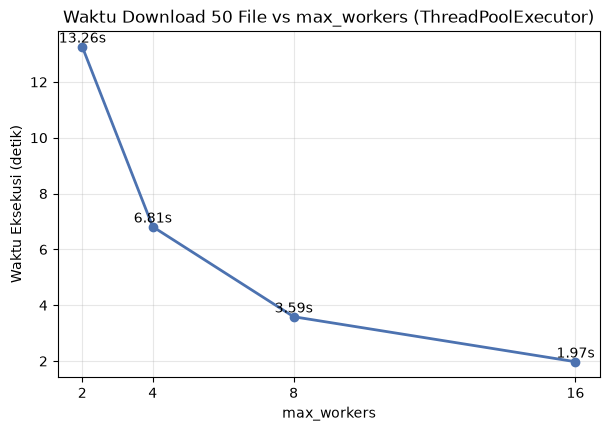

In [5]:
import random
import time
import matplotlib.pyplot as plt
from concurrent.futures import ThreadPoolExecutor, as_completed

random.seed(42)
JUMLAH_FILE = 50
daftar_file = [f"file_{i}.dat" for i in range(JUMLAH_FILE)]
latensi_simulasi = {f: random.uniform(0.3, 0.8) for f in daftar_file}

def download_file(nama_file):
    durasi = latensi_simulasi[nama_file]
    time.sleep(durasi)          # <-- di dunia nyata, ini requests.get(url)
    ukuran_kb = round(durasi * 1000)
    return f"{nama_file} ({ukuran_kb} KB)"

def jalankan_dengan_worker(n_worker):
    start = time.perf_counter()
    with ThreadPoolExecutor(max_workers=n_worker) as executor:
        futures = [executor.submit(download_file, f) for f in daftar_file]
        for fut in as_completed(futures):
            fut.result()
    return time.perf_counter() - start

daftar_worker = [2, 4, 8, 16]
waktu_eksekusi = []
for w in daftar_worker:
    waktu = jalankan_dengan_worker(w)
    waktu_eksekusi.append(waktu)
    print(f"max_workers={w:<3} -> waktu eksekusi = {waktu:.2f} detik")

plt.figure(figsize=(7, 4.5))
plt.plot(daftar_worker, waktu_eksekusi, marker='o', color="#4C72B0", linewidth=2)
for w, waktu in zip(daftar_worker, waktu_eksekusi):
    plt.text(w, waktu + 0.15, f"{waktu:.2f}s", ha='center')
plt.xlabel("max_workers")
plt.ylabel("Waktu Eksekusi (detik)")
plt.title(f"Waktu Download {JUMLAH_FILE} File vs max_workers (ThreadPoolExecutor)")
plt.xticks(daftar_worker)
plt.grid(alpha=0.3)
plt.show()

dari 2→4→8→16 worker, waktu eksekusi terus turun signifikan (13,25s → 1,97s), karena ini kerja I/O-bound (menunggu, bukan menghitung), jadi GIL tidak jadi penghambat dan makin banyak worker = makin banyak "penantian" yang tumpang tindih. Tapi ini tidak berarti makin banyak worker selalu makin cepat tanpa batas. Ada titik jenuh, yaitu ketika max_workers sudah ≥ jumlah file (di sini 50). Saya coba tambahkan sebagai pembuktian: